In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from io import StringIO
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.unicode_minus"] = False

print("Бібліотеки успішно імпортовано!")

Бібліотеки успішно імпортовано!


In [2]:

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Перші 5 рядків набору даних:")
display(df.head())

print("Розмір таблиці:", df.shape)
print("Назви стовпців:", df.columns.tolist())


Saving titanic.csv to titanic.csv
Перші 5 рядків набору даних:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Розмір таблиці: (891, 12)
Назви стовпців: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [3]:

print("Інформація про набір даних:")
df.info()

print("\nОписова статистика:")
display(df.describe(include="all"))

print("\nКількість пропущених значень:")
display(df.isnull().sum())

print("\nКількість дублікатів:")
print(df.duplicated().sum())


Інформація про набір даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Описова статистика:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN



Кількість пропущених значень:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Кількість дублікатів:
0


In [4]:

print("Загальна кількість пасажирів:", len(df))

print("Кількість пасажирів, що вижили:")
print(df["Survived"].value_counts())

survival_rate = df["Survived"].mean() * 100

print(f"Відсоток тих, хто вижив: {survival_rate:.2f}%")

print("\nВиживання залежно від статі:")
display(
    df.groupby("Sex")["Survived"]
      .agg(["count", "sum", "mean"])
)

print("\nВиживання залежно від класу:")
display(
    df.groupby("Pclass")["Survived"]
      .agg(["count", "sum", "mean"])
)


Загальна кількість пасажирів: 891
Кількість пасажирів, що вижили:
Survived
0    549
1    342
Name: count, dtype: int64
Відсоток тих, хто вижив: 38.38%

Виживання залежно від статі:


,count,sum,mean
Sex,,,
female,314,233,0.742038
male,577,109,0.188908



Виживання залежно від класу:


,count,sum,mean
Pclass,,,
1,216,136,0.629630
2,184,87,0.472826
3,491,119,0.242363


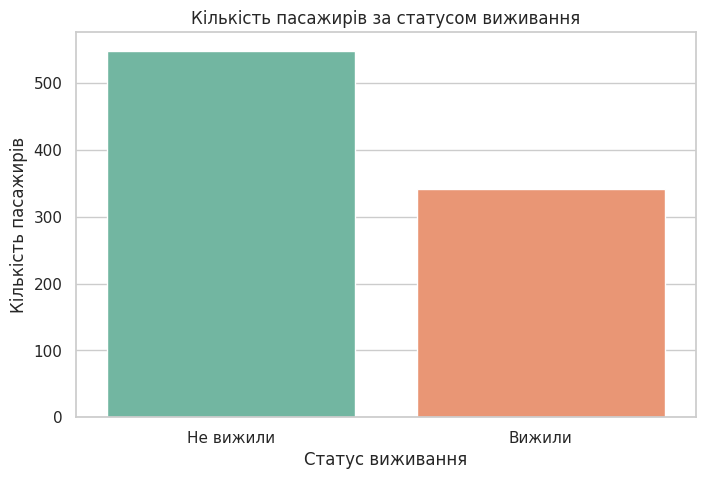

In [5]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Survived",
    hue="Survived",
    palette="Set2",
    legend=False
)

plt.title("Кількість пасажирів за статусом виживання")
plt.xlabel("Статус виживання")
plt.ylabel("Кількість пасажирів")
plt.xticks([0, 1], ["Не вижили", "Вижили"])

plt.show()


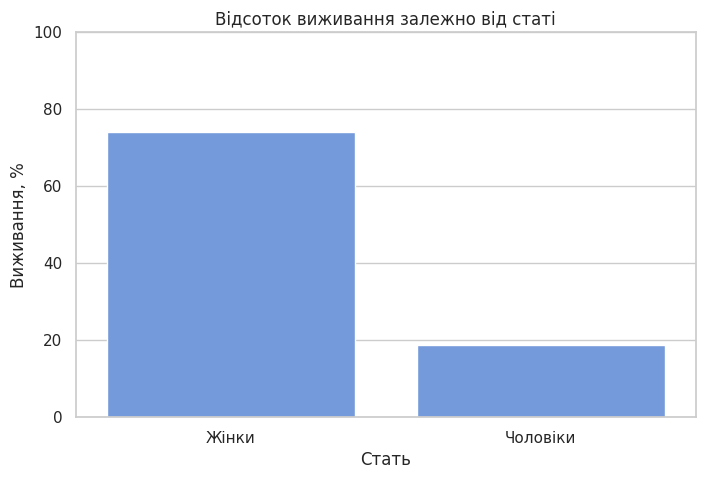

In [6]:

survival_by_sex = (
    df.groupby("Sex")["Survived"].mean() * 100
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=survival_by_sex.index,
    y=survival_by_sex.values,
    color="cornflowerblue"
)

plt.title("Відсоток виживання залежно від статі")
plt.xlabel("Стать")
plt.ylabel("Виживання, %")
plt.xticks([0, 1], ["Жінки", "Чоловіки"])
plt.ylim(0, 100)

plt.show()


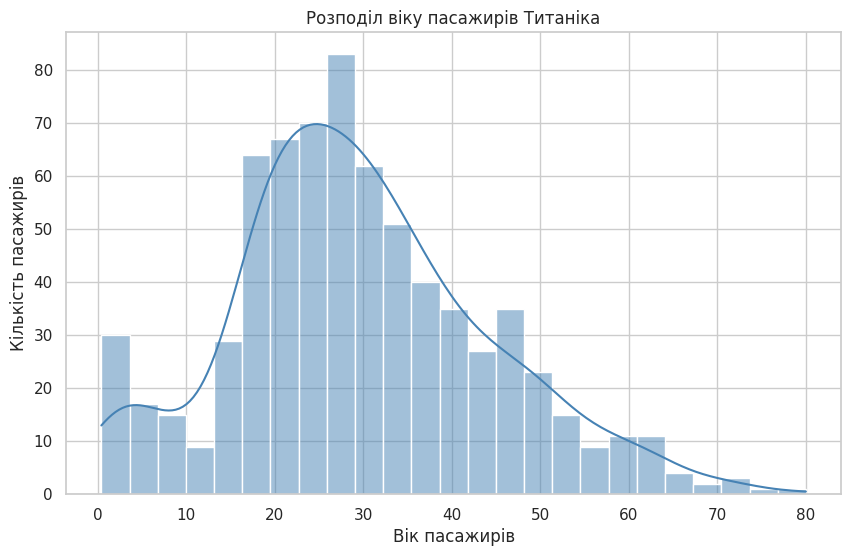

In [7]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Age",
    bins=25,
    kde=True,
    color="steelblue"
)

plt.title("Розподіл віку пасажирів Титаніка")
plt.xlabel("Вік пасажирів")
plt.ylabel("Кількість пасажирів")

plt.show()


In [8]:

url = "https://uk.wikipedia.org/wiki/Населення_України"

headers = {
    "User-Agent": "Mozilla/5.0 (compatible; DataAnalysis/1.0)"
}

response = requests.get(url, headers=headers, timeout=30)
response.raise_for_status()

tables = pd.read_html(StringIO(response.text))

print("Знайдено таблиць:", len(tables))

# Шукаємо таблицю, яка містить регіони
# та показники народжуваності за потрібні роки
birth_table = None

for table in tables:
    columns = [str(col) for col in table.columns]

    if (any("1950" in col for col in columns)
        and any("2019" in col for col in columns)
        and any("Регіон" in col for col in columns)):
        birth_table = table.copy()
        break

if birth_table is None:
    raise ValueError("Потрібну таблицю не знайдено!")

print("Таблицю народжуваності успішно знайдено!")
display(birth_table.head())


Знайдено таблиць: 70
Таблицю народжуваності успішно знайдено!


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,—,—
1,Вінницька,224.0,192.0,142.0,124,84,112,109,76
2,Волинська,247.0,250.0,179.0,153,112,148,141,101
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111,71
4,Донецька,271.0,214.0,140.0,109,61,98,82,—


In [9]:

birth_table.columns = [
    str(col).strip() for col in birth_table.columns
]

birth_table = birth_table.rename(
    columns={birth_table.columns[0]: "Регіон"}
)

birth_table["Регіон"] = (
    birth_table["Регіон"].astype(str).str.strip()
)

years = [
    "1950", "1960", "1970", "1990",
    "2000", "2012", "2014", "2019"
]

# Перетворюємо значення на числа
for year in years:
    birth_table[year] = (
        birth_table[year]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .str.replace("—", "", regex=False)
        .str.strip()
    )

    birth_table[year] = pd.to_numeric(
        birth_table[year], errors="coerce"
    )

print("Очищена таблиця:")
display(birth_table)

print("\nКількість пропущених значень:")
print(birth_table.isnull().sum())


Очищена таблиця:


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,230.0,206.0,160.0,130,73,126,NaN,NaN
1,Вінницька,224.0,192.0,142.0,124,84,112,109.0,76.0
2,Волинська,247.0,250.0,179.0,153,112,148,141.0,101.0
3,Дніпропетровська,204.0,204.0,151.0,123,71,112,111.0,71.0
4,Донецька,271.0,214.0,140.0,109,61,98,82.0,NaN
5,Житомирська,261.0,223.0,159.0,129,89,122,120.0,79.0
6,Закарпатська,314.0,273.0,207.0,168,115,151,146.0,104.0
7,Запорізька,219.0,197.0,150.0,124,71,106,106.0,68.0
8,Івано-Франківська,243.0,248.0,182.0,155,103,124,122.0,88.0
9,Київська,204.0,189.0,156.0,123,73,122,121.0,80.0



Кількість пропущених значень:
Регіон    0
1950      2
1960      1
1970      1
1990      0
2000      0
2012      0
2014      2
2019      4
dtype: int64


In [10]:

print("Описова статистика народжуваності:")
display(birth_table[years].describe().round(2))

ukraine = birth_table[
    birth_table["Регіон"] == "Україна"
]

regions = birth_table[
    birth_table["Регіон"] != "Україна"
].copy()

print("\nНайвища народжуваність у 2019 році:")
display(
    regions[["Регіон", "2019"]]
    .dropna()
    .sort_values("2019", ascending=False)
    .head(5)
)

print("\nНайнижча народжуваність у 2019 році:")
display(
    regions[["Регіон", "2019"]]
    .dropna()
    .sort_values("2019")
    .head(5)
)

print("\nСередній коефіцієнт за регіонами:")
display(regions[years].mean().round(2))


Описова статистика народжуваності:


,1950,1960,1970,1990,2000,2012,2014,2019
count,26.00,27.00,27.00,28.00,28.00,28.00,26.00,24.00
mean,230.92,207.48,155.85,130.43,82.07,116.46,111.42,80.21
std,28.22,29.36,18.70,15.28,15.57,16.36,20.12,14.50
min,186.00,163.00,127.00,108.00,61.00,94.00,51.00,60.00
25%,211.50,186.50,144.00,122.25,70.75,104.50,102.25,68.00
50%,226.00,204.00,152.00,126.00,78.50,114.50,111.50,79.00
75%,246.00,220.50,163.00,140.50,89.50,122.50,121.00,88.00
max,314.00,273.00,207.00,168.00,118.00,159.00,148.00,110.00



Найвища народжуваність у 2019 році:


,Регіон,2019
25,Київ,110.0
16,Рівненська,107.0
6,Закарпатська,104.0
2,Волинська,101.0
23,Чернівецька,92.0



Найнижча народжуваність у 2019 році:


,Регіон,2019
17,Сумська,60.0
24,Чернігівська,61.0
22,Черкаська,64.0
15,Полтавська,65.0
7,Запорізька,68.0



Середній коефіцієнт за регіонами:


,0
1950,231.04
1960,207.58
1970,156.00
1990,130.59
2000,82.22
2012,116.56
2014,111.44
2019,80.17


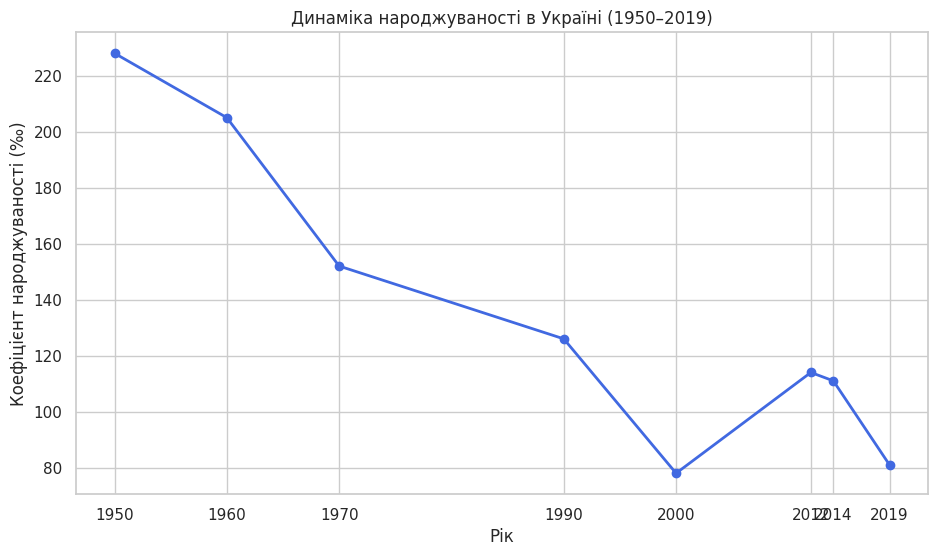

In [11]:

ukraine_values = ukraine[years].iloc[0]

plt.figure(figsize=(11, 6))

plt.plot(
    [int(y) for y in years],
    ukraine_values.values.astype(float),
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title("Динаміка народжуваності в Україні (1950–2019)")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності (‰)")
plt.xticks([int(y) for y in years])
plt.grid(True)

plt.show()


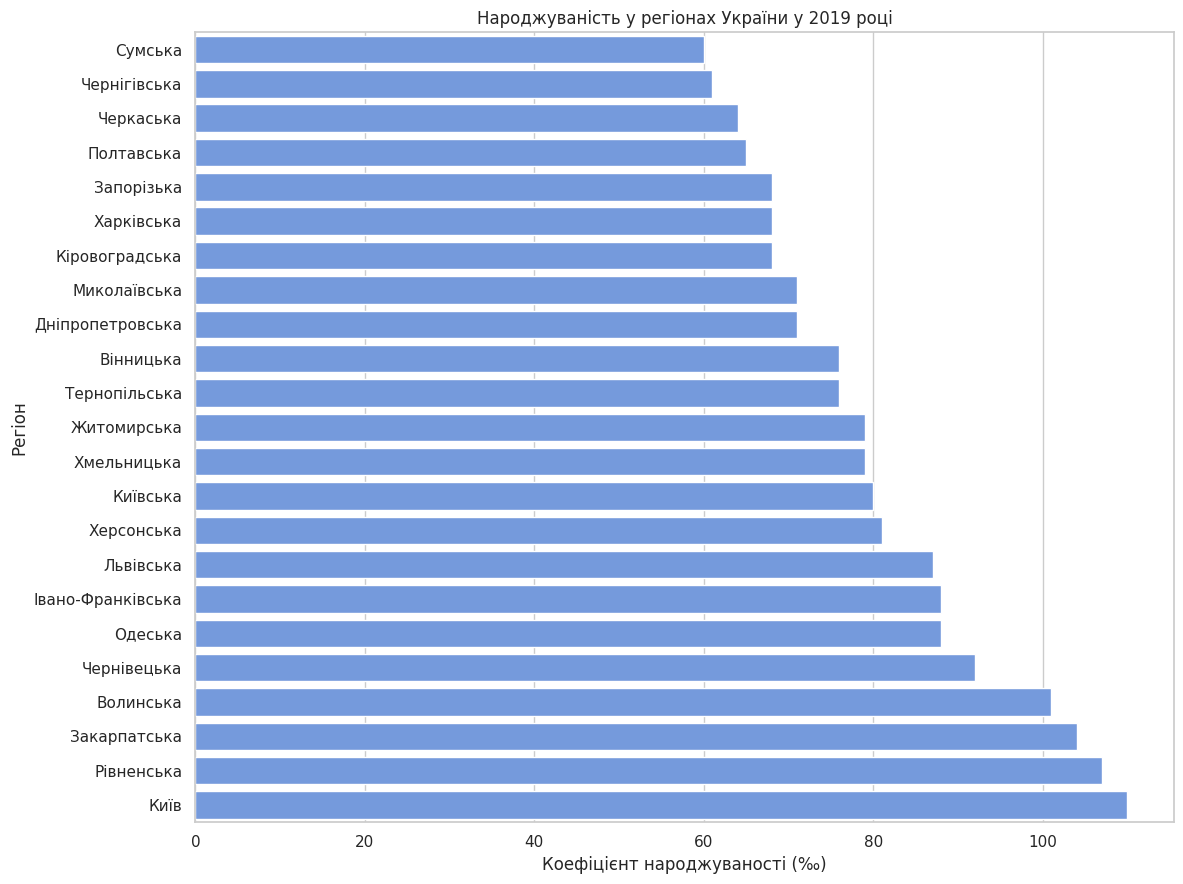

In [12]:

regions_2019 = (
    regions[["Регіон", "2019"]]
    .dropna()
    .sort_values("2019", ascending=True)
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=regions_2019,
    x="2019",
    y="Регіон",
    color="cornflowerblue"
)

plt.title("Народжуваність у регіонах України у 2019 році")
plt.xlabel("Коефіцієнт народжуваності (‰)")
plt.ylabel("Регіон")

plt.tight_layout()
plt.show()


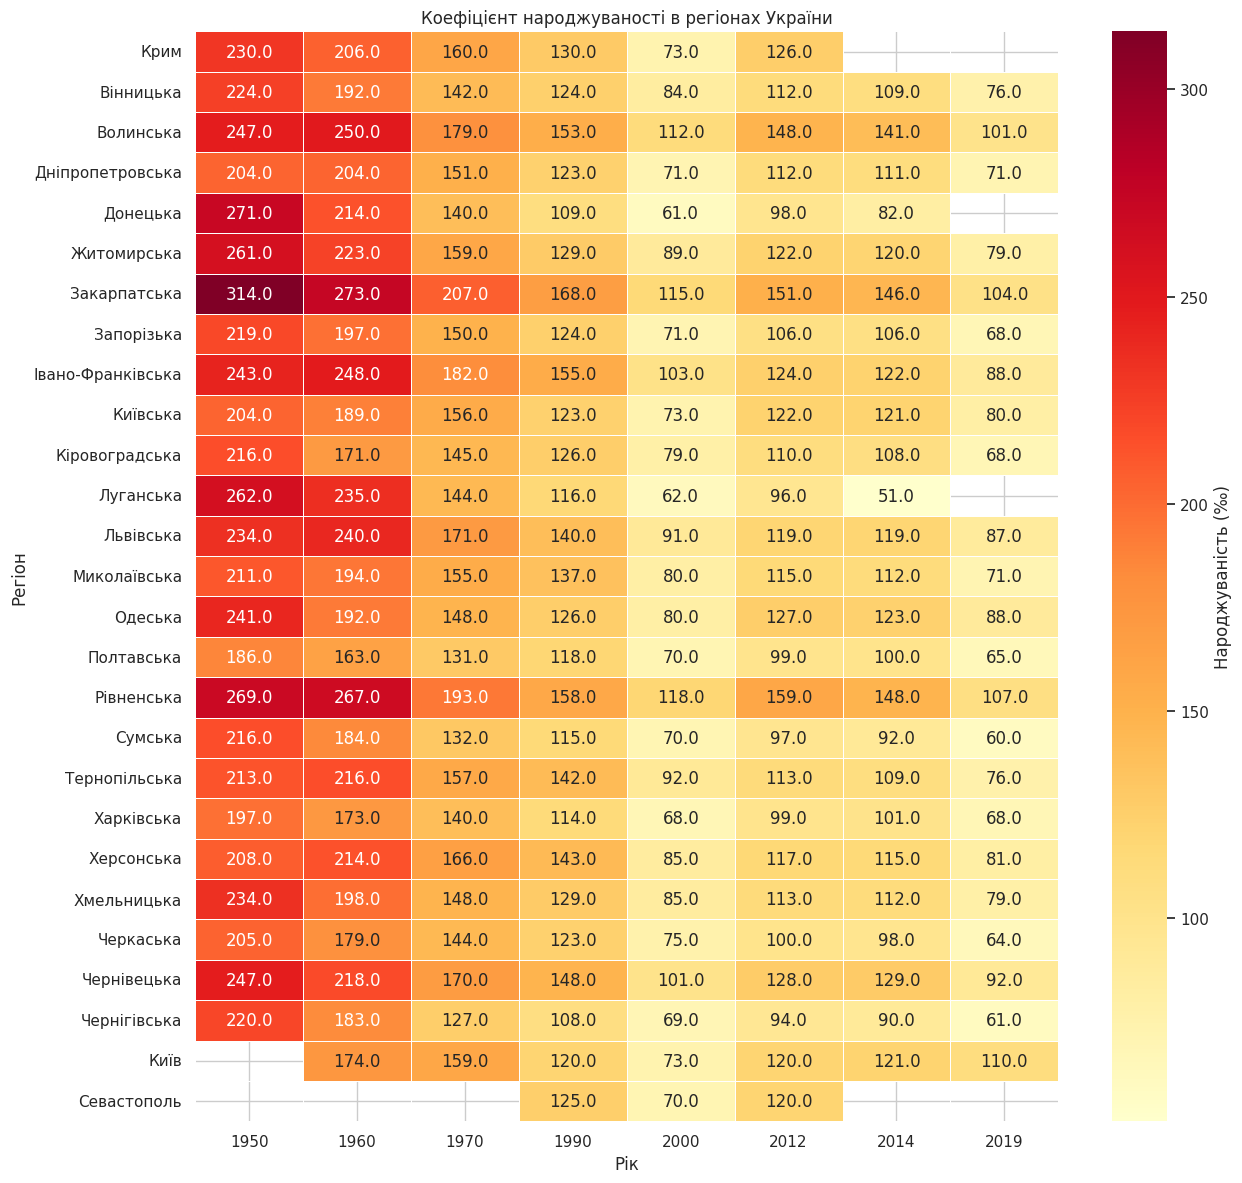

In [13]:

heatmap_data = regions.set_index("Регіон")[years]

plt.figure(figsize=(13, 12))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Народжуваність (‰)"}
)

plt.title("Коефіцієнт народжуваності в регіонах України")
plt.xlabel("Рік")
plt.ylabel("Регіон")

plt.tight_layout()
plt.show()
